# Problem sheet 6 (Exercise 30)

**30.** Implement for the minimization of the Rosenbrock function 
$$f(x_1, x_2) = (1 - x_1)^2 + 100(x_2 - x_1^2)^2,$$
the general line search algorithm 4.6 from the lecture notes using the algorithm from Remark 5.3 in the lecture notes to obtain the step size for: 
 * **(a)** $d^k := -\nabla f(x^k)$; 
 * **(b)** $d^k := -\begin{pmatrix} 1 & 0 \\ 0 & 2 \end{pmatrix} \nabla f(x^k)$.

How many iterations are needed to fulfill the stopping criterion $$\|\nabla f(x^k)\| \le \varepsilon,$$ where $\varepsilon$ takes the values $10^{-1}, 10^{-2}, 10^{-3}$? Provide a graphical representation of the implementation history.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Rosenbrock function and its gradient
def rosenbrock(v):
    x, y = v
    f = (1 - x)**2 + 100*(y - x**2)**2
    return f

def grad_rosenbrock(v):
    x, y = v
    grad_f = np.array([
        -2*(1 - x) - 400*x*(y - x**2),
        200*(y - x**2)
    ])
    return grad_f

In [ ]:
# algorithms

# auxiliary algorithm from remark 5.3
def auxiliary_algo(x, d, sigma= 0.3, rho=0.7, t0 = 1):
    
    def phi(t):
        return rosenbrock(x + t*d)
    def phi_prime(t):
        return np.dot(np.transpose(grad_rosenbrock(x+ t*d)), d)
    def psi(t):
        return rosenbrock(x) + sigma*t*(np.dot(np.transpose(grad_rosenbrock(x)), d))
    #print('starting phase A')
    t_k = t0 
    while True:
        if phi(t_k) >= psi(t_k):         # comparing parts fo the WP
            a, b = 0, t_k
            break 
        elif phi_prime(t_k) >= rho*phi_prime(0):
            return t_k
        elif phi_prime(t_k) < rho*phi_prime(0): 
            t_k = 2*t_k

    #print('starting phase B')
    a_k, b_k = a, b
    while True:
        t_k = (a_k + b_k)/2
        if phi(t_k) >= psi(t_k):
            a_k, b_k = a_k, t_k
        elif phi_prime(t_k) >= rho*phi_prime(0):
            return t_k
        else: a_k, b_k = t_k, b_k


# main algorithm from remark 4.6
def general_line_search(x0, epsilon, descent_direction = "a"):
    num_it = 0       # counts number of iterations
    vectors =[]      # for graphical representation
    vectors.append(x0)

    x_k = x0
    while np.linalg.norm(grad_rosenbrock(x_k)) > epsilon:
        if descent_direction == "a":
            d_k = - grad_rosenbrock(x_k)
        else:
            d_k = -np.array([[1, 0], [0, 2]]) @ grad_rosenbrock(x_k)

        t_k = auxiliary_algo(x_k, d_k)

        x_k = x_k + t_k*d_k
        vectors.append(x_k)
        num_it += 1

    #print('done')
    #print(num_it)
    return num_it, vectors



In [36]:
epsilons = [1e-1, 1e-2, 1e-3]
#x0 = np.random.rand(2)
x0 = [-1.2, 1.6]
N_iter_a = []
N_iter_b = []

for e in epsilons:
  #print(f"Epsilon = {e}")
  num_a, _ = general_line_search(x0, e, "a")
  num_b, _ = general_line_search(x0, e, "b")
  N_iter_a.append(num_a)
  N_iter_b.append(num_b)


data = {
  "Epsilon": epsilons,
  "Number of iterations (a)": N_iter_a,
  "Number of iterations (b)": N_iter_b
}
df= pd.DataFrame(data)
df

,Epsilon,Number of iterations (a),Number of iterations (b)
0,0.100,701,389
1,0.010,1417,847
2,0.001,1604,1679


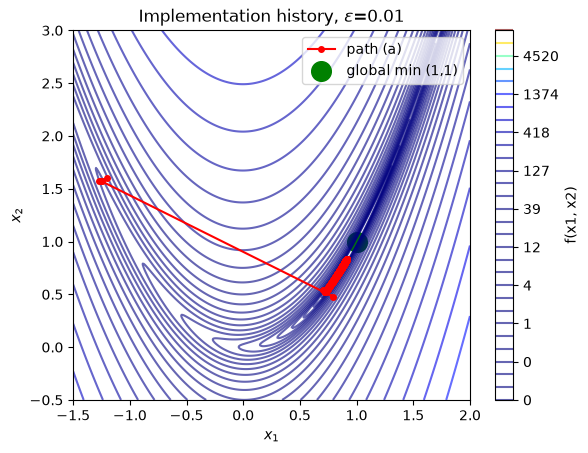

In [31]:
# decsent direction as in case (a)
_, vectors_a = general_line_search(x0, 1e-1, "a")
path_a = np.array(vectors_a)

x1 = np.linspace(-1.5, 2.0, 400)
x2 = np.linspace(-0.5, 3.0, 400)
X1, X2 = np.meshgrid(x1, x2)
Z = (1 - X1) ** 2 + 100 * (X2 - X1**2) ** 2

plt.contour(X1, X2, Z, levels=np.logspace(-1, 4, 30),cmap="jet", alpha=0.6)
plt.colorbar(label="f(x1, x2)")
plt.plot(
    path_a[:, 0],
    path_a[:, 1],
    "ro-",
    linewidth=1.5,
    markersize=4,
    label="path (a)",
)
plt.scatter(1, 1, color="green", s=200, label="global min (1,1)")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Implementation history, $ \\epsilon $=0.01")
plt.legend()
plt.show()

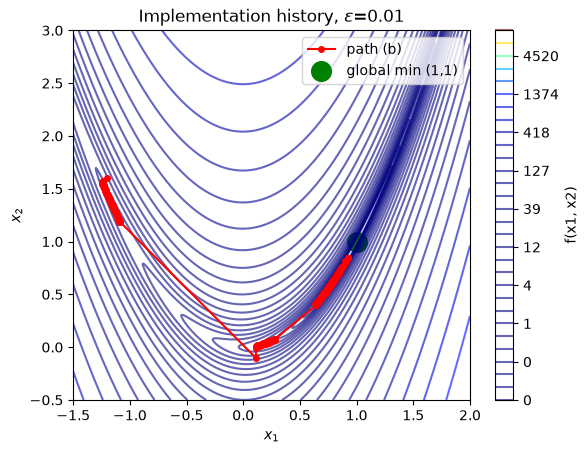

In [32]:
# descent direction as in case (b)
_, vectors = general_line_search(x0, 1e-1, "b")
path = np.array(vectors)

x1 = np.linspace(-1.5, 2.0, 400)
x2 = np.linspace(-0.5, 3.0, 400)
X1, X2 = np.meshgrid(x1, x2)
Z = (1 - X1) ** 2 + 100 * (X2 - X1**2) ** 2

plt.contour(X1, X2, Z, levels=np.logspace(-1, 4, 30),cmap="jet", alpha=0.6)
plt.colorbar(label="f(x1, x2)")
plt.plot(
    path[:, 0],
    path[:, 1],
    "ro-",
    linewidth=1.5,
    markersize=4,
    label="path (b)",
)
plt.scatter(1, 1, color="green", s=200, label="global min (1,1)")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Implementation history, $ \\epsilon $=0.01")
plt.legend()
plt.show()